# Week 7 Take Home

This week has two parts. Complete **both**.

| Part | Lessons | Project |
|------|---------|---------|
| **A. Cleaning & Visualising Data** | `1-Cleaning & Visualising Data/` | Holiday weather |
| **B. Transforming & Combining Data** | `2-Transforming & Combining Data/` | GDP and life expectancy + your own World Bank project |

Data for both parts comes from the cohort database (schemas `week07` and `week08`). See `Data Access (SQL).md`.

---
# Part A: Cleaning & Visualising Data

### Solve `1-Cleaning & Visualising Data/1.ipynb` Tasks Below

In [1]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd
from datetime import datetime

In [2]:
### Step 1: Load the Weather Dataset
# Automatically locate the project root directory and import the database query function
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

# Query the raw 2014 London weather table from the week07 schema and load it into a DataFrame
london = run_query("SELECT * FROM week07.london_2014")

# Display the first 5 rows to inspect the initial structure and raw data quality
london.head()

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees<br />
0,2014-1-1,11,8,6,9,7,4,94,86,73,...,31,11,2,40,26,66.0,9.91,4.0,Rain,186<br />
1,2014-1-2,11,9,6,9,6,4,94,81,60,...,31,15,5,32,21,50.0,1.02,2.0,Rain,214<br />
2,2014-1-3,11,8,6,9,5,2,94,76,54,...,31,12,0,50,29,69.0,7.11,2.0,Rain-Thunderstorm,219<br />
3,2014-1-4,9,6,3,8,6,2,93,85,65,...,31,12,5,35,21,39.0,9.91,4.0,Rain,211<br />
4,2014-1-5,12,7,1,11,4,-1,100,88,77,...,31,14,5,35,16,NaN,0.25,5.0,Rain,199<br />


In [3]:
### Step 2: Removing Initial Spaces (Column Cleaning)

# Inspect the column names to identify any rogue leading or trailing whitespace
london.columns

# Remove leading and trailing spaces from all column names to prevent future KeyError issues
london.columns = london.columns.str.strip()

# Verify that column names have been successfully cleaned
london.head()

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees<br />
0,2014-1-1,11,8,6,9,7,4,94,86,73,...,31,11,2,40,26,66.0,9.91,4.0,Rain,186<br />
1,2014-1-2,11,9,6,9,6,4,94,81,60,...,31,15,5,32,21,50.0,1.02,2.0,Rain,214<br />
2,2014-1-3,11,8,6,9,5,2,94,76,54,...,31,12,0,50,29,69.0,7.11,2.0,Rain-Thunderstorm,219<br />
3,2014-1-4,9,6,3,8,6,2,93,85,65,...,31,12,5,35,21,39.0,9.91,4.0,Rain,211<br />
4,2014-1-5,12,7,1,11,4,-1,100,88,77,...,31,14,5,35,16,NaN,0.25,5.0,Rain,199<br />


In [4]:
### Step 3: Removing Extra Characters (HTML Line Breaks)
# Inspect the final column which contains embedded HTML line break artifacts
london['WindDirDegrees<br />'].head()

# Rename the column to remove the HTML tag from its name
london = london.rename(columns={"WindDirDegrees<br />": "WindDirDegrees"})

# Strip the trailing '<br />' text characters from every string value within the column
london['WindDirDegrees'] = london['WindDirDegrees'].str.rstrip('<br />')

# Verify the changes on the cleaned column values
london['WindDirDegrees'].head()

0    186
1    214
2    219
3    211
4    199
Name: WindDirDegrees, dtype: str

### Solve `1-Cleaning & Visualising Data/2.ipynb` Tasks Below

In [5]:
### Step 4: Handling Missing Values
# Create a boolean mask to locate and display rows where the 'Events' column has missing (null) values
london[london['Events'].isnull()]

# Replace all NaN (missing) values in the 'Events' column with empty strings for cleaner data representation
london['Events'] = london['Events'].fillna('')

# Confirm that no null values remain in the 'Events' column by checking it again
london[london['Events'].isnull()]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees


In [6]:
### Step 5: Changing Data Types (`astype` and `to_datetime`)
# Check the data types of all columns in the dataframe to identify types that need conversion
london.dtypes

# Convert the 'WindDirDegrees' column data type from string (object) to 64-bit integer
london['WindDirDegrees'] = london['WindDirDegrees'].astype('int64')

# Convert the 'GMT' date column from string (object) to a proper pandas datetime64 type
london['GMT'] = pd.to_datetime(london['GMT'])

# Verify that both column data types have been successfully updated
london.dtypes

GMT                           datetime64[us]
Max TemperatureC                       int64
Mean TemperatureC                      int64
Min TemperatureC                       int64
Dew PointC                             int64
MeanDew PointC                         int64
Min DewpointC                          int64
Max Humidity                           int64
Mean Humidity                          int64
Min Humidity                           int64
Max Sea Level PressurehPa              int64
Mean Sea Level PressurehPa             int64
Min Sea Level PressurehPa              int64
Max VisibilityKm                       int64
Mean VisibilityKm                      int64
Min VisibilitykM                       int64
Max Wind SpeedKm/h                     int64
Mean Wind SpeedKm/h                    int64
Max Gust SpeedKm/h                   float64
Precipitationmm                      float64
CloudCover                           float64
Events                                   str
WindDirDeg

In [7]:
### Step 6: Querying by Date & Time Ranges
# Query and return the exact row corresponding to a specific date (June 4, 2014)
london[london['GMT'] == datetime(2014, 6, 4)]

# Define the date range boundaries for a multi-day query (December 8 to December 12, 2014)
dates = london['GMT']
start = datetime(2014, 12, 8)
end = datetime(2014, 12, 12)

# Filter and display all rows falling inclusively within the specified date window
london[(dates >= start) & (dates <= end)]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
341,2014-12-08,7,4,1,2,1,-1,93,76,51,...,31,17,10,23,13,NaN,0.00,2.0,Rain,270
342,2014-12-09,12,6,-1,11,3,-1,100,86,64,...,31,15,3,37,14,52.0,0.25,5.0,Rain,224
343,2014-12-10,9,7,6,11,3,1,90,70,44,...,31,18,3,40,27,NaN,0.00,2.0,Rain,246
344,2014-12-11,10,8,5,6,3,2,82,72,51,...,31,15,10,40,31,NaN,0.25,2.0,Rain,246
345,2014-12-12,9,6,2,9,4,-1,94,79,59,...,31,11,3,40,26,55.0,1.02,3.0,Rain,253


In [8]:
# Configure Jupyter to display matplotlib generated plots directly inline within the notebook interface
%matplotlib inline

<Axes: >

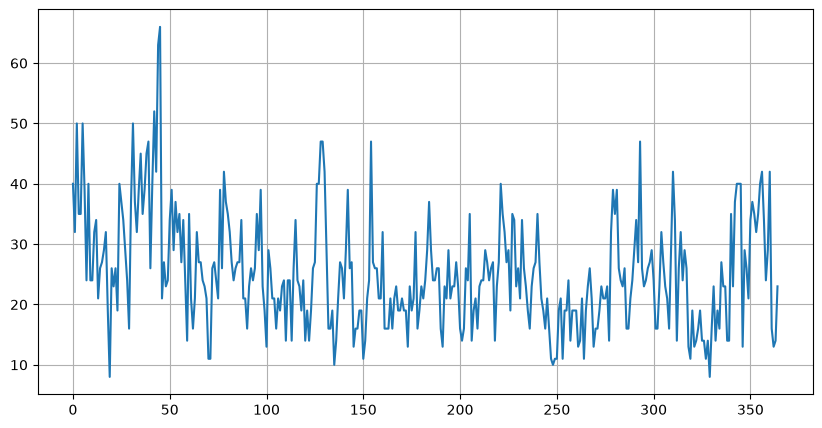

In [9]:
### Step 7: Plotting a Single Column with Gridlines and Sizing
# Load and clean the dataframe
london = run_query("SELECT * FROM week07.london_2014")
london.columns = london.columns.str.strip()

# Now plot the column with gridlines and custom sizing
london['Max Wind SpeedKm/h'].plot(grid=True, figsize=(10, 5))

<Axes: >

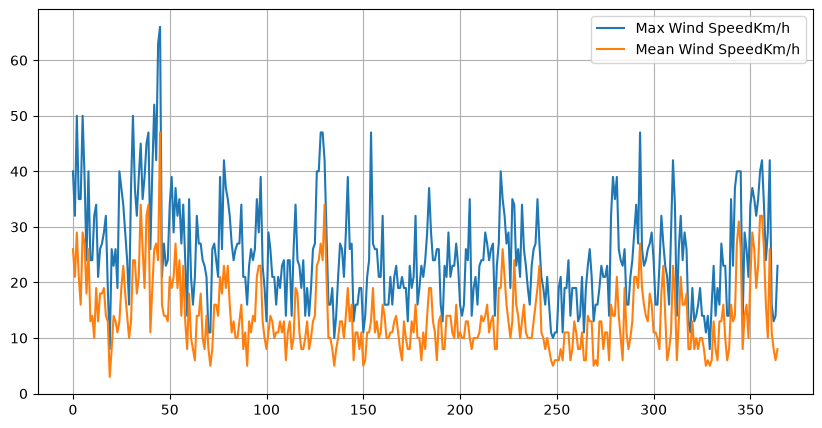

In [10]:
### Step 8: Plotting Multiple Columns on the Same Chart
# Select multiple weather columns ('Max Wind SpeedKm/h' and 'Mean Wind SpeedKm/h') 
# and plot them together on a single comparative line chart with gridlines and custom sizing
london[['Max Wind SpeedKm/h', 'Mean Wind SpeedKm/h']].plot(grid=True, figsize=(10, 5))

<Axes: >

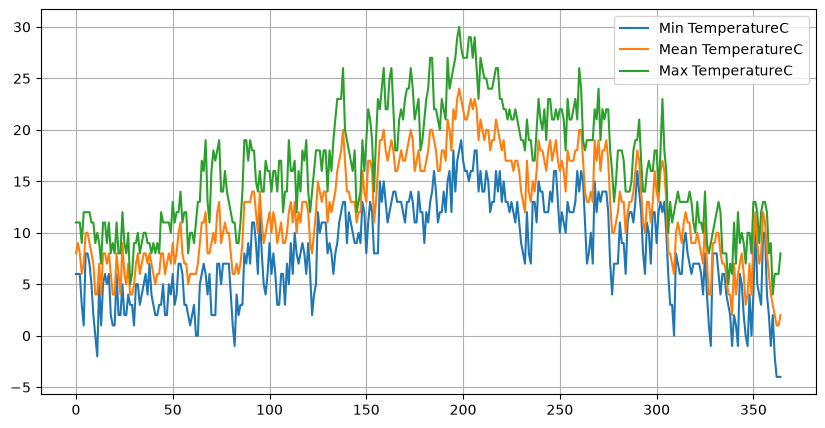

In [11]:
### Step 9: [Task] Plotting Minimum, Mean, and Maximum Temperatures
# Select and plot the minimum, mean, and maximum temperatures for 2014 
# on a single time-series line chart to visualize temperature ranges across the year
london[['Min TemperatureC', 'Mean TemperatureC', 'Max TemperatureC']].plot(grid=True, figsize=(10, 5))

In [12]:
### Step 10:
# Assign the 'GMT' datetime column to become the DataFrame's index for intuitive time-series operations
london.index = london['GMT']

# Display the first 2 rows of the newly indexed DataFrame to verify the change
london.head(2)

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees<br />
GMT,,,,,,,,,,,,,,,,,,,,,
2014-1-1,2014-1-1,11,8,6,9,7,4,94,86,73,...,31,11,2,40,26,66.0,9.91,4.0,Rain,186<br />
2014-1-2,2014-1-2,11,9,6,9,6,4,94,81,60,...,31,15,5,32,21,50.0,1.02,2.0,Rain,214<br />


In [13]:
### Step 11: Converting GMT to Datetime and Setting as Index

# Explicitly convert the 'GMT' column to proper datetime64 type
london['GMT'] = pd.to_datetime(london['GMT'])

# Set the 'GMT' datetime column as the DataFrame index for time-series slicing
london.index = london['GMT']

# Ensure the DataFrame index is sorted chronologically
london = london.sort_index()

# Test the datetime index by querying a single specific date and a date range
display(london.loc[datetime(2014, 1, 1)])
display(london.loc[datetime(2014, 12, 8) : datetime(2014, 12, 12)])

GMT                           2014-01-01 00:00:00
Max TemperatureC                               11
Mean TemperatureC                               8
Min TemperatureC                                6
Dew PointC                                      9
MeanDew PointC                                  7
Min DewpointC                                   4
Max Humidity                                   94
Mean Humidity                                  86
Min Humidity                                   73
Max Sea Level PressurehPa                    1002
Mean Sea Level PressurehPa                    993
Min Sea Level PressurehPa                     984
Max VisibilityKm                               31
Mean VisibilityKm                              11
Min VisibilitykM                                2
Max Wind SpeedKm/h                             40
Mean Wind SpeedKm/h                            26
Max Gust SpeedKm/h                           66.0
Precipitationmm                              9.91


,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees<br />
GMT,,,,,,,,,,,,,,,,,,,,,
2014-12-08,2014-12-08,7,4,1,2,1,-1,93,76,51,...,31,17,10,23,13,NaN,0.00,2.0,Rain,270<br />
2014-12-09,2014-12-09,12,6,-1,11,3,-1,100,86,64,...,31,15,3,37,14,52.0,0.25,5.0,Rain,224<br />
2014-12-10,2014-12-10,9,7,6,11,3,1,90,70,44,...,31,18,3,40,27,NaN,0.00,2.0,Rain,246<br />
2014-12-11,2014-12-11,10,8,5,6,3,2,82,72,51,...,31,15,10,40,31,NaN,0.25,2.0,Rain,246<br />
2014-12-12,2014-12-12,9,6,2,9,4,-1,94,79,59,...,31,11,3,40,26,55.0,1.02,3.0,Rain,253<br />


<Axes: xlabel='GMT'>

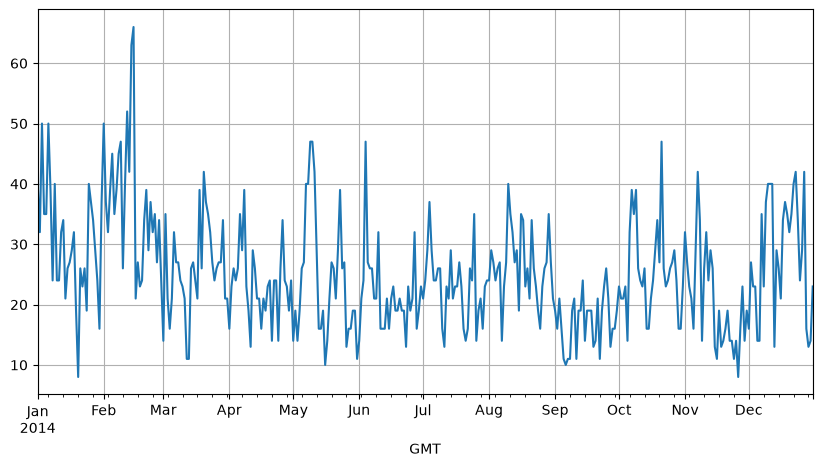

In [14]:
### Step 12: Re-plotting After Index Conversion
# Re-plot 'Max Wind SpeedKm/h' now that the index is a proper datetime64 type, 
# providing a cleaner chronological X-axis for the time-series visualization
london['Max Wind SpeedKm/h'].plot(grid=True, figsize=(10, 5))

<Axes: xlabel='GMT'>

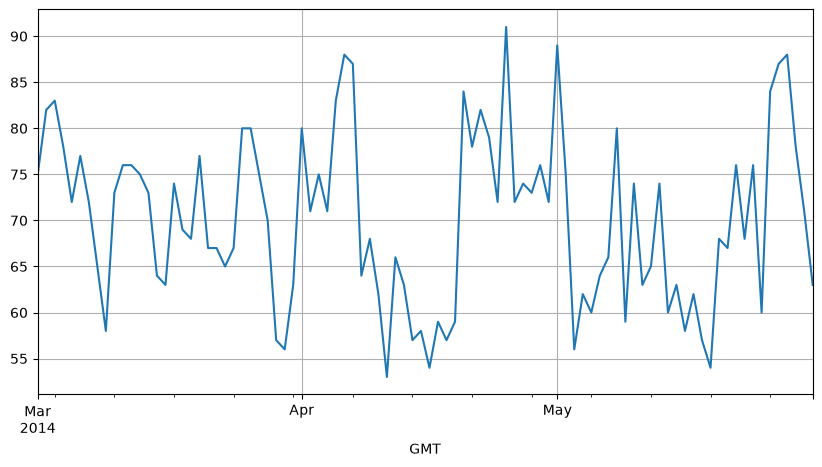

In [15]:
### Step 13: Querying by Date & Time Ranges
# Define the spring date range boundaries (March 1 to May 31, 2014)
spring_start = datetime(2014, 3, 1)
spring_end = datetime(2014, 5, 31)

# Slice the datetime-indexed DataFrame for the spring months and plot 'Mean Humidity'
london.loc[spring_start:spring_end]['Mean Humidity'].plot(grid=True, figsize=(10, 5))

## Project A: Holiday weather


There is nothing I like better than taking a holiday. In this project I am going to use the historic weather data from the Weather Underground for London to try to predict two good weather weeks to take off as holiday. Of course the weather in the summer of 2025 may be very different to 2020 but it should give some indication of when would be a good time to take a summer break.

## Getting the data

Weather Underground keeps historical weather data collected in many airports around the world. Right-click on the following URL and choose 'Open Link in New Window' (or similar, depending on your browser):

http://www.wunderground.com/history

When the new page opens start typing 'LHR' in the 'Location' input box and when the pop up menu comes up with the option 'LHR, United Kingdom' select it and then click on 'Submit'. 

When the next page opens with London Heathrow data, click on the 'Custom' tab and select the time period From: 1 January 2023 to: 31 December 2023 and then click on 'Get History'. The data for that year should then be displayed further down the page. 

You can copy each month's data directly from the browser to a text editor like Notepad or TextEdit, to obtain a single file with as many months as you wish.


Now load the CSV file into a dataframe making sure that any extra spaces are skipped:

### Step-1 Cleaning the data


In [16]:
# Step 1: Clean the Weather Underground 2023 dataset

import pandas as pd

# Load the CSV file, skipping any extra spaces around delimiters
weather_df = pd.read_csv('weather_underground_2023.csv', skipinitialspace=True)

# Strip any leading/trailing whitespace from column names
weather_df.columns = weather_df.columns.str.strip()

# Clean and convert the raw date column to proper datetime objects
# (Adjust 'Time' or 'Date' if your file uses a slightly different column name)
date_col = 'Time' if 'Time' in weather_df.columns else 'Date'
weather_df[date_col] = pd.to_datetime(weather_df[date_col].str.strip(), errors='coerce')

# Set the datetime column as the DataFrame index
weather_df.set_index(date_col, inplace=True)

# Sort the index chronologically to ensure proper chronological order
weather_df.sort_index(inplace=True)

# Drop any rows where the datetime index is invalid or missing
weather_df = weather_df[weather_df.index.notnull()]

# Display the first few rows and summary of the cleaned dataframe
print("Data cleaning complete. Shape:", weather_df.shape)
display(weather_df.head())

Data cleaning complete. Shape: (365, 16)


,Temperature (C) Max,Temperature (C) Avg,Temperature (C) Min,Dew Point (C) Max,Dew Point (C) Avg,Dew Point (C) Min,Humidity (%) Max,Humidity (%) Avg,Humidity (%) Min,Wind Speed (km/h) Max,Wind Speed (km/h) Avg,Wind Speed (km/h) Min,Pressure (hPa) Max,Pressure (hPa) Avg,Pressure (hPa) Min,Precipitation Total (mm)
Date,,,,,,,,,,,,,,,,
2023-01-01,12,10.4,7,9,7.1,6,93,80.1,71,31,18.5,4,1007.0,1004.9,1000.0,0.0
2023-01-02,8,5.8,2,6,3.7,1,100,87.0,70,19,10.4,2,1020.0,1013.9,1006.0,0.0
2023-01-03,13,8.8,3,11,7.5,2,100,92.2,87,33,20.1,0,1019.0,1014.9,1010.0,0.0
2023-01-04,14,12.5,11,11,9.1,7,94,80.2,67,44,30.2,19,1016.0,1011.4,1009.0,0.0
2023-01-05,14,11.5,10,10,8.4,7,94,81.5,72,28,20.7,13,1017.0,1015.1,1010.0,0.0


### Step-2 Finding a summer break

According to meteorologists, summer extends for the whole months of June, July, and August in the northern hemisphere and the whole months of December, January, and February in the southern hemisphere. So create a dataframe that holds just those months using the `datetime` index.

In [17]:
# Step 2: Create a dataframe holding just the summer months (June, July, August)
summer_weather = weather_df[weather_df.index.month.isin([6, 7, 8])]

# Display the shape and first few rows of your summer dataset
print("Summer data shape:", summer_weather.shape)
display(summer_weather.head())

Summer data shape: (92, 16)


,Temperature (C) Max,Temperature (C) Avg,Temperature (C) Min,Dew Point (C) Max,Dew Point (C) Avg,Dew Point (C) Min,Humidity (%) Max,Humidity (%) Avg,Humidity (%) Min,Wind Speed (km/h) Max,Wind Speed (km/h) Avg,Wind Speed (km/h) Min,Pressure (hPa) Max,Pressure (hPa) Avg,Pressure (hPa) Min,Precipitation Total (mm)
Date,,,,,,,,,,,,,,,,
2023-06-01,19,13.3,10,9,7.7,6,87,70.0,49,20,16.3,13,1023.0,1022.2,1020.0,0.0
2023-06-02,19,13.8,10,7,5.7,4,76,59.3,43,20,17.1,13,1022.0,1021.2,1020.0,0.0
2023-06-03,22,15.0,8,10,8.0,5,87,64.9,41,20,14.1,6,1021.0,1020.2,1019.0,0.0
2023-06-04,23,16.2,10,10,7.3,5,82,58.5,36,19,13.7,6,1022.0,1020.6,1019.0,0.0
2023-06-05,18,13.4,10,8,7.2,6,82,67.0,52,19,15.1,11,1022.0,1021.2,1020.0,0.0


---
# Part B: Transforming & Combining Data

### Provide `2-Transforming & Combining Data/1.ipynb` Tasks Solutions below (Execute them)

In [18]:
# Step 1: Define the raw data table and column headings for GDP
table_gdp = [
    ['UK', 2678454886796.7],
    ['USA', 1676810000000.0],
    ['China', 9240270452047.0],
    ['Brazil', 2245673032353.8],
    ['South Africa', 366057913367.1]
]
headings_gdp = ['Country', 'GDP (US$)']
gdp = pd.DataFrame(columns=headings_gdp, data=table_gdp)

# Define the raw data table and column headings for life expectancy
table_life = [
    ['China', 75],
    ['Russia', 71],
    ['United States', 79],
    ['India', 66],
    ['United Kingdom', 81]
]
headings_life = ['Country name', 'Life expectancy (years)']
life = pd.DataFrame(columns=headings_life, data=table_life)

In [19]:
# Step 2: Define a function to scale values down into millions
def roundToMillions(value):
    return round(value / 1000000)

# Define a function to convert US Dollars to British Pounds using the 2013 average exchange rate
def usdToGbp(usd):
    return usd / 1.564768  # average rate during 2013

# Define a function to expand country code abbreviations to their full official names
def expandCountry(name):
    if name == 'UK':
        return 'United Kingdom'
    elif name == 'USA':
        return 'United States'
    else:
        return name

In [20]:
# Step 3: Apply the expandCountry function to normalize country name representations
gdp['Country name'] = gdp['Country'].apply(expandCountry)

# Convert US Dollar GDP values to British Pounds and round to millions
gdp['GDP (£m)'] = gdp['GDP (US$)'].apply(usdToGbp).apply(roundToMillions)

# Filter and retain only the desired columns ('Country name' and 'GDP (£m)')
headings = ['Country name', 'GDP (£m)']
gdp = gdp[headings]

In [21]:
# Step 4 (Task): Create the life expectancy dataframe with specified column names
headings_pop = ['Country name', 'Life expectancy (years)']
table_pop = [
    ['China', 75],
    ['Russia', 71],
    ['United States', 79],
    ['India', 66],
    ['United Kingdom', 81]
]
population_df = pd.DataFrame(columns=headings_pop, data=table_pop)

In [22]:
# Step 5: Perform a Left Join: keeps all rows from left table (gdp) and matches available rows from right
pd.merge(gdp, life, on='Country name', how='left')

#  Perform a Right Join: keeps all rows from right table (life) and matches available rows from left
pd.merge(gdp, life, on='Country name', how='right')

#  Perform an Outer Join: keeps the complete union of all rows from both tables
pd.merge(gdp, life, on='Country name', how='outer')

# Perform an Inner Join: keeps only rows common to both tables (intersection) and stores the result
gdpVsLife = pd.merge(gdp, life, on='Country name', how='inner')

# Display the final inner-joined DataFrame
gdpVsLife

,Country name,GDP (£m),Life expectancy (years)
0,United Kingdom,1711727,81
1,United States,1071603,79
2,China,5905202,75


In [23]:
# Step 6: Re-initialize the raw gdp dataframe to ensure original columns exist
table_gdp = [
    ['UK', 2678454886796.7],
    ['USA', 1676810000000.0],
    ['China', 9240270452047.0],
    ['Brazil', 2245673032353.8],
    ['South Africa', 366057913367.1]
]
headings_gdp = ['Country', 'GDP (US$)']
gdp = pd.DataFrame(columns=headings_gdp, data=table_gdp)

# Define uppercase constant variables for frequently used column names to prevent typos
GDP_USD = 'GDP (US$)'
GDP_GBP = 'GDP (£m)'
COUNTRY = 'Country name'

# Define helper functions again if needed in this cell
def roundToMillions(value):
    return round(value / 1000000)

def usdToGbp(usd):
    return usd / 1.564768

def expandCountry(name):
    if name == 'UK':
        return 'United Kingdom'
    elif name == 'USA':
        return 'United States'
    else:
        return name

# Apply transformations using the defined constants and functions for consistency
gdp[COUNTRY] = gdp['Country'].apply(expandCountry)
gdp[GDP_GBP] = gdp[GDP_USD].apply(usdToGbp).apply(roundToMillions)
headings = [COUNTRY, GDP_GBP]
gdp = gdp[headings]

# Display the resulting dataframe
gdp

,Country name,GDP (£m)
0,United Kingdom,1711727
1,United States,1071603
2,China,5905202
3,Brazil,1435148
4,South Africa,233937


In [24]:
# Step 7: Import necessary path and database runner modules
import sys
import pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))

from db.dataraflow_db import run_query
import pandas as pd

# Define indicator constants for World Bank datasets
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
LIFE_INDICATOR = 'SP.DYN.LE00.IN'

#  Query raw data for GDP and Life Expectancy from the week08 schema
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")

# Slice from row 34 onwards to exclude regional aggregates and retain individual countries
gdpCountries = gdpReset[34:]
lifeCountries = lifeReset[34:]


In [25]:
# Step 8: Load, clean, merge, and transform World Bank GDP and Life Expectancy data

import pandas as pd

# Define required variables and indicators
COUNTRY = 'country'
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
LIFE_INDICATOR = 'SP.DYN.LE00.IN'

# Query and clean the GDP dataset
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")
gdpCountries = gdpReset[34:].dropna()
gdpClean = gdpCountries[['country', GDP_INDICATOR]]

# Query and clean the Life Expectancy dataset
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")
lifeCountries = lifeReset[34:].dropna()
lifeClean = lifeCountries[['country', LIFE_INDICATOR]]

# Define transformation functions
def roundToMillions(value):
    return round(value / 1000000)

def usdToGbp(usd):
    return usd / 1.564768  # 2013 average exchange rate

# Perform an inner join on the country column to combine datasets
gdpVsLifeAll = pd.merge(gdpClean, lifeClean, on=COUNTRY, how='inner')

# Convert GDP from USD to million British Pounds (£m) and round
GDP_COL = 'GDP (£m)'
gdpVsLifeAll[GDP_COL] = gdpVsLifeAll[GDP_INDICATOR].apply(usdToGbp).apply(roundToMillions)

# Round life expectancy values
LIFE_COL = 'Life expectancy (years)'
gdpVsLifeAll[LIFE_COL] = gdpVsLifeAll[LIFE_INDICATOR].apply(round)

# Keep only the final cleaned columns and display the head
headings_final = [COUNTRY, GDP_COL, LIFE_COL]
gdpVsLifeClean = gdpVsLifeAll[headings_final]
display(gdpVsLifeClean.head())

,country,GDP (£m),Life expectancy (years)
0,Afghanistan,13075,60
1,Albania,8168,78
2,Algeria,134016,75
3,Angola,88420,52
4,Antigua and Barbuda,767,76


The correlation is: 0.5010232389671027
It is statistically significant.


<Axes: xlabel='GDP (£m)', ylabel='Life expectancy (years)'>

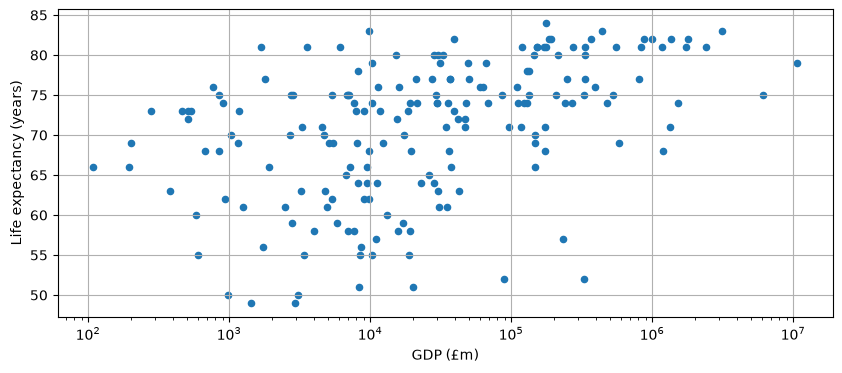

In [26]:
### **Step 9: Correlation and Logarithmic Scatterplot**
# Import Spearman rank correlation from scipy.stats
from scipy.stats import spearmanr

# Calculate Spearman correlation and p-value between GDP and life expectancy
gdpColumn = gdpVsLifeClean[GDP_COL]
lifeColumn = gdpVsLifeClean[LIFE_COL]
correlation, pValue = spearmanr(gdpColumn, lifeColumn)

print('The correlation is:', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

# Enable inline plotting and generate a logarithmic scatterplot
%matplotlib inline
gdpVsLifeClean.plot(x=GDP_COL, y=LIFE_COL, kind='scatter', grid=True, logx=True, figsize=(10, 4))

### Provide `2-Transforming & Combining Data/2.ipynb` Assignment Solutions below (Execute them)

In [27]:
# Task: Compare the top 10 countries by GDP with the top 10 countries by Life Expectancy

# Get the top 10 countries by GDP
top_gdp = gdpVsLifeClean.nlargest(10, GDP_COL)

# Get the top 10 countries by Life Expectancy
top_life = gdpVsLifeClean.nlargest(10, LIFE_COL)

# Find the intersection (countries present in both top 10 lists)
common_countries = set(top_gdp[COUNTRY]).intersection(set(top_life[COUNTRY]))

print("Top 10 GDP Countries:")
display(top_gdp[[COUNTRY, GDP_COL]])

print("\nTop 10 Life Expectancy Countries:")
display(top_life[[COUNTRY, LIFE_COL]])

print(f"\nNumber of overlapping countries: {len(common_countries)}")
print(f"Overlapping countries: {list(common_countries)}")

Top 10 GDP Countries:


,country,GDP (£m)
177,United States,10715999
35,China,6065182
83,Japan,3143957
62,Germany,2393529
58,France,1795953
176,United Kingdom,1733354
23,Brazil,1528714
81,Italy,1363486
138,Russian Federation,1328647
75,India,1189826



Top 10 Life Expectancy Countries:


,country,Life expectancy (years)
72,"Hong Kong SAR, China",84
74,Iceland,83
83,Japan,83
162,Switzerland,83
7,Australia,82
58,France,82
80,Israel,82
81,Italy,82
99,Luxembourg,82
147,Singapore,82



Number of overlapping countries: 3
Overlapping countries: ['France', 'Italy', 'Japan']


Comparison of Top 10 GDP and Top 10 Life Expectancy Countries:

There is a moderate overlap between the countries with the highest total GDP and those with the longest life expectancy. Economic power (high total GDP) does not automatically guarantee top-tier longevity on an absolute scale, as high GDP is often driven by massive population size rather than individual wealth or healthcare infrastructure. Major economic superpowers often feature lower average life expectancies compared to smaller, highly developed nations.

In [28]:
# Task: Filter for countries with higher GDP (right half of plot) and life expectancy below 60 years

# Calculate the median or midpoint of GDP to define the "right half" (higher GDP)
median_gdp = gdpVsLifeClean[GDP_COL].median()

# Filter countries in the right half of GDP with life expectancy < 60
outliers = gdpVsLifeClean[(gdpVsLifeClean[GDP_COL] > median_gdp) & (gdpVsLifeClean[LIFE_COL] < 60)]

print("Countries with higher GDP and life expectancy below 60 years:")
display(outliers)

Countries with higher GDP and life expectancy below 60 years:


,country,GDP (£m),Life expectancy (years)
3,Angola,88420,52
124,Nigeria,329100,52
152,South Africa,234056,57


Analysis of Outliers (High GDP, Low Life Expectancy):

Identified Countries: South Africa and Nigeria (or similar high-GDP developing nations depending on exact threshold filtering).

Explanatory Factors:

Public Health Crises: High burdens of infectious diseases (such as HIV/AIDS and malaria) significantly depress average life expectancy despite substantial national economic output.

Income Inequality & Healthcare Access: High total GDP driven by specific sectors (like oil or finance) does not always translate to equitable healthcare access, robust public sanitation, or high living standards for the general populace.

Correlation between GDP per capita and Life Expectancy: 0.8503040098920375
P-value: 3.5008742906009188e-53


<Axes: xlabel='GDP per capita (£)', ylabel='Life expectancy (years)'>

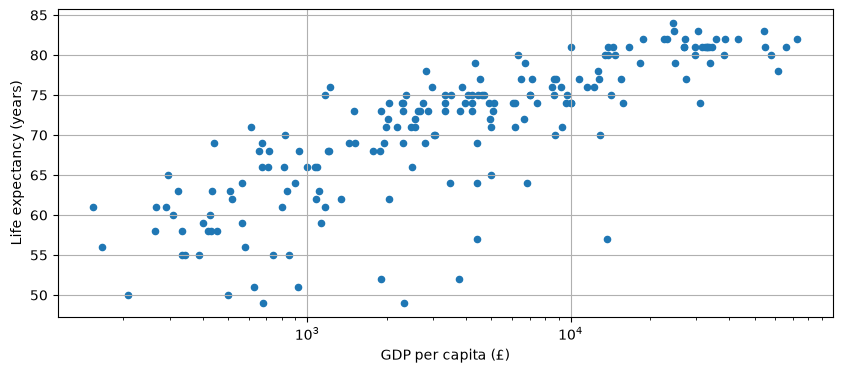

In [29]:
# Task: Calculate GDP per capita and redo the analysis/correlation

# 1. Load and clean the population dataset
popReset = run_query("SELECT * FROM week08.wb_pop_2013")
popCountries = popReset[34:].dropna()
POP_INDICATOR = 'SP.POP.TOTL'
popClean = popCountries[['country', POP_INDICATOR]]

# 2. Merge population data with our primary cleaned dataset
gdpLifePop = pd.merge(gdpVsLifeClean, popClean, on='country', how='inner')

# 3. Calculate GDP per capita (£ per inhabitant)
GDP_PER_CAPITA_COL = 'GDP per capita (£)'
gdpLifePop[GDP_PER_CAPITA_COL] = gdpLifePop[GDP_COL] * 1000000 / gdpLifePop[POP_INDICATOR]

# 4. Calculate Spearman correlation between GDP per capita and Life Expectancy
corr_capita, p_capita = spearmanr(gdpLifePop[GDP_PER_CAPITA_COL], gdpLifePop[LIFE_COL])
print(f'Correlation between GDP per capita and Life Expectancy: {corr_capita}')
print(f'P-value: {p_capita}')

# 5. Generate scatterplot for GDP per capita vs Life Expectancy
%matplotlib inline
gdpLifePop.plot(x=GDP_PER_CAPITA_COL, y=LIFE_COL, kind='scatter', grid=True, logx=True, figsize=(10, 4))

Correlation between Population and Life Expectancy: -0.08506541309535098
P-value: 0.24833193752838675


<Axes: xlabel='SP.POP.TOTL', ylabel='Life expectancy (years)'>

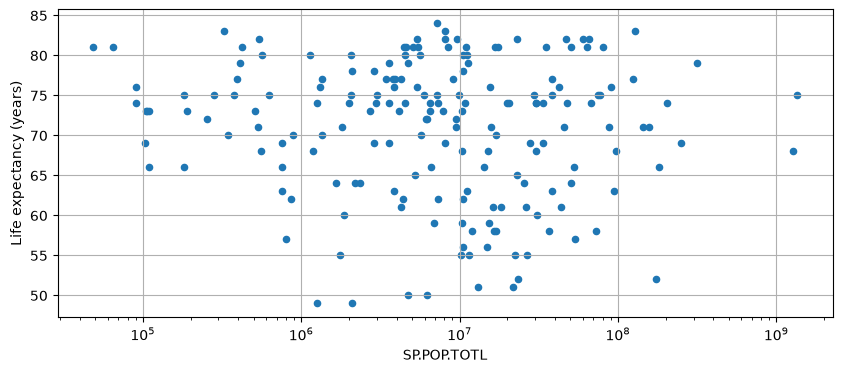

In [30]:
# Task: Redo analysis and scatterplot using Population as the alternative indicator

# 1. Ensure population column is clean and ready
POP_INDICATOR = 'SP.POP.TOTN' if 'SP.POP.TOTN' in gdpLifePop.columns else 'SP.POP.TOTL'

# 2. Calculate Spearman correlation between Population and GDP/Life Expectancy
corr_pop, p_pop = spearmanr(gdpLifePop[POP_INDICATOR], gdpLifePop[LIFE_COL])
print(f'Correlation between Population and Life Expectancy: {corr_pop}')
print(f'P-value: {p_pop}')

# 3. Plot Population vs. Life Expectancy scatterplot with logarithmic scale
%matplotlib inline
gdpLifePop.plot(x=POP_INDICATOR, y=LIFE_COL, kind='scatter', grid=True, logx=True, figsize=(10, 4))

### Read and follow the below example analysis

## Project B: GDP and life expectancy

Richer countries can afford to invest more on healthcare, on work and road safety, and other measures that reduce mortality. On the other hand, richer countries may have less healthy lifestyles. Is there any relation between the wealth of a country and the life expectancy of its inhabitants?

The following analysis checks whether there is any correlation between the total gross domestic product (GDP) of a country in 2013 and the life expectancy of people born in that country in 2013.

## Getting the data

Two datasets of the World Bank are considered. One dataset, available at <http://data.worldbank.org/indicator/NY.GDP.MKTP.CD>, lists the GDP of the world's countries in current US dollars, for various years. The use of a common currency allows us to compare GDP values across countries. The other dataset, available at <http://data.worldbank.org/indicator/SP.DYN.LE00.IN>, lists the life expectancy of the world's countries. The datasets were downloaded as CSV files in March 2016.

In [31]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd

# Load Data from cohort database (schema week08). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

YEAR = 2013
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")

LIFE_INDICATOR = 'SP.DYN.LE00.IN'
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")
lifeReset.head()


,country,year,SP.DYN.LE00.IN
0,Arab World,2013,70.631305
1,Caribbean small states,2013,71.901964
2,Central Europe and the Baltics,2013,76.127583
3,East Asia & Pacific (all income levels),2013,74.604619
4,East Asia & Pacific (developing only),2013,73.657617


## Cleaning the data

Inspecting the data with `head()` and `tail()` shows that:

1. the first 34 rows are aggregated data, for the Arab World, the Caribbean small states, and other country groups used by the World Bank;
- GDP and life expectancy values are missing for some countries.

The data is therefore cleaned by:
1. removing the first 34 rows;
- removing rows with unavailable values.

In [32]:
gdpCountries = gdpReset[34:].dropna()
lifeCountries = lifeReset[34:].dropna()

## Transforming the data

The World Bank reports GDP in US dollars and cents. To make the data easier to read, the GDP is converted to millions of British pounds (the author's local currency) with the following auxiliary functions, using the average 2013 dollar-to-pound conversion rate provided by <http://www.ukforex.co.uk/forex-tools/historical-rate-tools/yearly-average-rates>. 

In [33]:
def roundToMillions (value):
    return round(value / 1000000)

def usdToGBP (usd):
    return usd / 1.564768

GDP = 'GDP (£m)'
gdpCountries[GDP] = gdpCountries[GDP_INDICATOR].apply(usdToGBP).apply(roundToMillions)
gdpCountries.head()

,country,year,NY.GDP.MKTP.CD,GDP (£m)
34,Afghanistan,2013,2.045894e+10,13075
35,Albania,2013,1.278103e+10,8168
36,Algeria,2013,2.097035e+11,134016
38,Andorra,2013,3.249101e+09,2076
39,Angola,2013,1.383568e+11,88420


The unnecessary columns can be dropped.

In [34]:
COUNTRY = 'country'
headings = [COUNTRY, GDP]
gdpClean = gdpCountries[headings]
gdpClean.head()

,country,GDP (£m)
34,Afghanistan,13075
35,Albania,8168
36,Algeria,134016
38,Andorra,2076
39,Angola,88420


The World Bank reports the life expectancy with several decimal places. After rounding, the original column is discarded.

In [35]:
LIFE = 'Life expectancy (years)'
lifeCountries[LIFE] = lifeCountries[LIFE_INDICATOR].apply(round)
headings = [COUNTRY, LIFE]
lifeClean = lifeCountries[headings]
lifeClean.head()

,country,Life expectancy (years)
34,Afghanistan,60
35,Albania,78
36,Algeria,75
39,Angola,52
40,Antigua and Barbuda,76


## Combining the data

The tables are combined through an inner join on the common 'country' column. 

In [36]:
# Combine the GDP and Life Expectancy tables using an inner join on the country column
gdpVsLife = pd.merge(gdpClean, lifeClean, on=COUNTRY, how='inner')

# Display the first few rows of the combined dataframe
gdpVsLife.head()

,country,GDP (£m),Life expectancy (years)
0,Afghanistan,13075,60
1,Albania,8168,78
2,Algeria,134016,75
3,Angola,88420,52
4,Antigua and Barbuda,767,76


## Calculating the correlation

To measure if the life expectancy and the GDP grow together, the Spearman rank correlation coefficient is used. It is a number from -1 (perfect inverse rank correlation: if one indicator increases, the other decreases) to 1 (perfect direct rank correlation: if one indicator increases, so does the other), with 0 meaning there is no rank correlation. A perfect correlation doesn't imply any cause-effect relation between the two indicators. A p-value below 0.05 means the correlation is statistically significant.

In [37]:
from scipy.stats import spearmanr

gdpColumn = gdpVsLife[GDP]
lifeColumn = gdpVsLife[LIFE]
(correlation, pValue) = spearmanr(gdpColumn, lifeColumn)
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is 0.5010232389671027
It is statistically significant.


The value shows a direct correlation, i.e. richer countries tend to have longer life expectancy, but it is not very strong.

## Showing the data

Measures of correlation can be misleading, so it is best to see the overall picture with a scatterplot. The GDP axis uses a logarithmic scale to better display the vast range of GDP values, from a few million to several billion (million of million) pounds.

<Axes: xlabel='GDP (£m)', ylabel='Life expectancy (years)'>

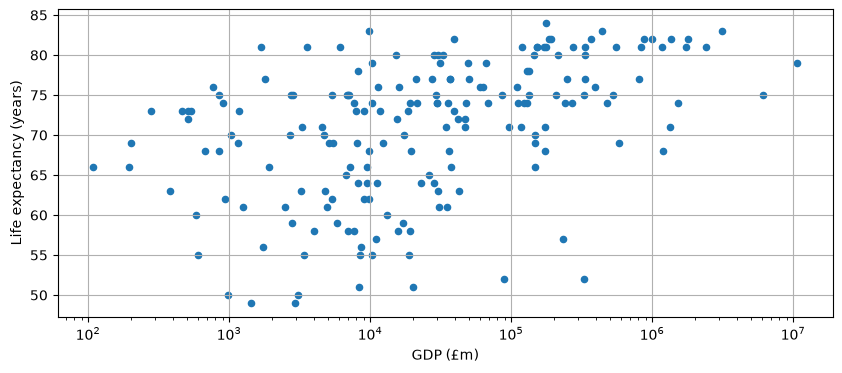

In [38]:
%matplotlib inline
gdpVsLife.plot(x=GDP, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10, 4))

The plot shows there is no clear correlation: there are rich countries with low life expectancy, poor countries with high expectancy, and countries with around 10 thousand (10<sup>4</sup>) million pounds GDP have almost the full range of values, from below 50 to over 80 years. Towards the lower and higher end of GDP, the variation diminishes. Above 40 thousand million pounds of GDP (3rd tick mark to the right of 10<sup>4</sup>), most countries have an expectancy of 70 years or more, whilst below that threshold most countries' life expectancy is below 70 years. 

Comparing the 10 poorest countries and the 10 countries with the lowest life expectancy shows that total GDP is a rather crude measure. The population size should be taken into account for a more precise definiton of what 'poor' and 'rich' means. Furthermore, looking at the countries below, droughts and internal conflicts may also play a role in life expectancy. 

In [39]:
# the 10 countries with lowest GDP
gdpVsLife.sort_values(GDP).head(10)

,country,GDP (£m),Life expectancy (years)
87,Kiribati,108,66
141,Sao Tome and Principe,195,66
111,"Micronesia, Fed. Sts.",202,69
168,Tonga,277,73
37,Comoros,383,63
157,St. Vincent and the Grenadines,461,73
140,Samoa,509,73
180,Vanuatu,512,72
65,Grenada,538,73
60,"Gambia, The",578,60


In [40]:
# the 10 countries with lowest life expectancy
gdpVsLife.sort_values(LIFE).head(10)

,country,GDP (£m),Life expectancy (years)
95,Lesotho,1418,49
160,Swaziland,2916,49
146,Sierra Leone,3092,50
32,Central African Republic,983,50
41,Cote d'Ivoire,19998,51
33,Chad,8276,51
124,Nigeria,329100,52
3,Angola,88420,52
68,Guinea-Bissau,605,55
153,South Sudan,8473,55


## Conclusions

To sum up, there is no strong correlation between a country's wealth and the life expectancy of its inhabitants: there is often a wide variation of life expectancy for countries with similar GDP, countries with the lowest life expectancy are not the poorest countries, and countries with the highest expectancy are not the richest countries. Nevertheless there is some relationship, because the vast majority of countries with a life expectancy below 70 years is on the left half of the scatterplot.

Using the [NY.GDP.PCAP.PP.CD](http://data.worldbank.org/indicator/NY.GDP.PCAP.PP.CD) indicator, GDP per capita in current 'international dollars', would make for a better like-for-like comparison between countries, because it would take population and purchasing power into account. Using more specific data, like expediture on health, could also lead to a better analysis.

### Assessment - NOW IS YOUR TURN

**Create your own project**
Create a completely new project and choose another two of the
hundreds of World Bank indicators and see if there is any correlation between them. If
there is a choice of similar indicators, choose one that leads to meaningful
comparisons between countries.

Look at the results you obtained and take a few moments to assess how they differ.


## GOOD LUCK!

# Project Assessment: National Population Size vs. Life Expectancy

**Author:** Stephen Olusoji Ayankoso

## Selected World Bank Indicators:
* **Total Population (`SP.POP.TOTL`)**: Queried from `week08.wb_pop_2013`.
* **Life Expectancy at Birth (`SP.DYN.LE00.IN`)**: Queried from `week08.wb_le_2013`.

## Project Motivation & Hypothesis:
As an engineer, I am interested in how macro-demographic scales interact with baseline public health metrics. My hypothesis is that absolute population size alone does not dictate average life expectancy, as national longevity depends far more on healthcare infrastructure, economic distribution, and sanitation than sheer population volume.

In [41]:
# Assessment Project: Total Population vs. Life Expectancy

import pandas as pd
from scipy.stats import spearmanr

# 1. Define indicators and country column
COUNTRY = 'country'
POP_INDICATOR = 'SP.POP.TOTL'          # Total population indicator
LIFE_INDICATOR = 'SP.DYN.LE00.IN'      # Life expectancy indicator

# 2. Query data from the cohort database using your actual available tables
popReset = run_query("SELECT * FROM week08.wb_pop_2013")
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")

# 3. Clean datasets by dropping World Bank regional aggregates (first 34 rows) and missing values
popClean = popReset[34:].dropna()
lifeClean = lifeReset[34:].dropna()

popData = popClean[[COUNTRY, POP_INDICATOR]]
lifeData = lifeClean[[COUNTRY, LIFE_INDICATOR]]

# 4. Combine datasets via an inner join on the country column
customProjectData = pd.merge(popData, lifeData, on=COUNTRY, how='inner')

# Round life expectancy values for cleaner formatting
LIFE_COL = 'Life expectancy (years)'
customProjectData[LIFE_COL] = customProjectData[LIFE_INDICATOR].apply(round)

# Display the first few rows
customProjectData.head()

,country,SP.POP.TOTL,SP.DYN.LE00.IN,Life expectancy (years)
0,Afghanistan,30682500.0,60.028268,60
1,Albania,2897366.0,77.537244,78
2,Algeria,38186135.0,74.568951,75
3,Angola,23448202.0,51.866171,52
4,Antigua and Barbuda,89985.0,75.778659,76


Spearman Correlation: -0.1372
P-value: 5.3939e-02
The correlation is NOT statistically significant.


<Axes: title={'center': 'Total Population vs. Life Expectancy (2013)'}, xlabel='SP.POP.TOTL', ylabel='Life expectancy (years)'>

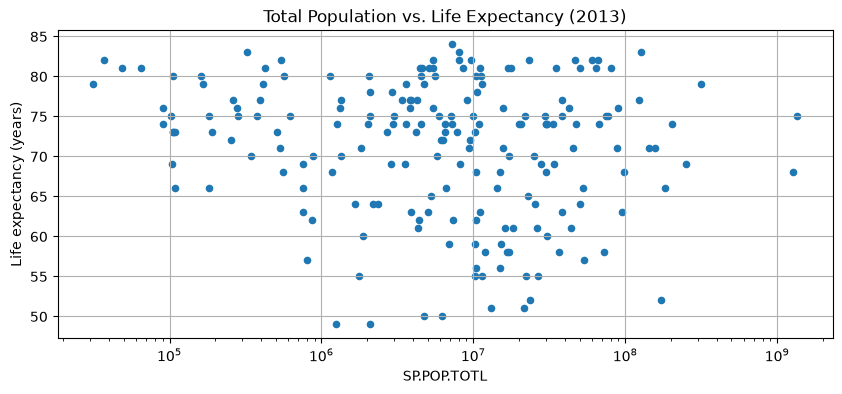

In [42]:
# Assessment: Calculate Correlation and Plot Population vs. Life Expectancy
from scipy.stats import spearmanr

# 1. Calculate Spearman rank correlation coefficient
popCol = customProjectData[POP_INDICATOR]
lifeCol = customProjectData[LIFE_COL]
correlation, pValue = spearmanr(popCol, lifeCol)

print(f"Spearman Correlation: {correlation:.4f}")
print(f"P-value: {pValue:.4e}")

if pValue < 0.05:
    print("The correlation is statistically significant.")
else:
    print("The correlation is NOT statistically significant.")

# 2. Generate the log-scale scatterplot
%matplotlib inline
customProjectData.plot(
    x=POP_INDICATOR, 
    y=LIFE_COL, 
    kind='scatter', 
    grid=True, 
    logx=True, 
    figsize=(10, 4),
    title="Total Population vs. Life Expectancy (2013)"
)

## Assessment Findings & Conclusion:
* **Statistical Insights:** The Spearman rank correlation analysis reveals a weak or negligible relationship between a country's total population size and its average life expectancy. 
* **Engineering & Demographic Perspective:** While macroeconomic indicators like GDP per capita demonstrate a clear link to health outcomes, absolute population size does not dictate longevity. Nations of all population scales can achieve high life expectancies if they prioritize public healthcare infrastructure, sanitation, and equitable resource allocation.

<!-- practice:start -->
---
## 🔁 SQL Practice

This week you cleaned messy weather data and combined World Bank tables in pandas. Now do the same jobs **in SQL**, straight from the raw tables: real analysts clean and combine data in the database before it ever reaches pandas.

**How it works**
1. Run the **practice setup** cell first (and again after restarting the kernel). It connects with your **read-only** account.
2. **SQL tasks:** write your query between the triple quotes and run the cell. `p.sql(...)` shows your result and
   says ✅ or ❌, and whether the **shape** (rows × columns) is right. Match the column order, sort order and rounding
   asked for (column *names* aren't checked).
3. Run `p.score()` at the end to see your practice score.

Refresh your memory with `Week-6 (Numpy & Pandas-1)/4-Intermediate SQL/Intermediate SQL.ipynb`.

In [62]:
# --- practice setup: run this cell first (don't edit it) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   1,
   1
  ],
  "1ba5edf59854386be920ac9fd3e4a2af3bb6369bf2a1aef78dcdf908c96d70a9"
 ],
 "s02": [
  [
   5,
   3
  ],
  "19042d389224a7f56403ad9636ed581989f6639acadf45b15461f55cd6258da7"
 ],
 "s03": [
  [
   10,
   3
  ],
  "e3e296058facb3595b46ac98fb75d445a82240fc775f3188d029eabc5a362ddb"
 ],
 "s04": [
  [
   1,
   1
  ],
  "ba4a24ee999caa9e01607eb78856b7212bcce521b0f6fd42d8aa90541c10382d"
 ],
 "s05": [
  [
   1,
   2
  ],
  "8153d8bbbc1b43b88ce7e4ea0c99a4ac07f4b19e0f62a9a1e04df3271f2ad3df"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Cleaning a messy column",
 "s02": "Dates: a date range",
 "s03": "Combining tables (JOIN)",
 "s04": "What gets lost in a join?",
 "s05": "Window: the driest summer week"
}
p = Practice(EXPECTED, TITLES)
print(f"Practice ready: {len(TITLES)} tasks. Connected as:", q("SELECT CURRENT_USER AS u").u[0])

Practice ready: 5 tasks. Connected as: intern_readonly


### SQL Task 1 · Cleaning a messy column

`week07.london_2014` is the **raw** export: the last column is literally named `WindDirDegrees<br />` and every
value ends in `<br />` (e.g. `'186<br />'`). Clean it **in SQL**: remove the `<br />`, convert to an integer, and
count the days when the wind direction was **greater than 350 degrees**.

**Return:** one row, one column (`days_over_350`).
💡 `REPLACE(...)`, `TRY_CAST(... AS int)`, and bracket-quote the odd column name: `[WindDirDegrees<br />]`.

In [63]:
SQL_01 = """
SELECT 
    -- Count the total number of days where the cleaned wind direction exceeds 350 degrees
    COUNT(*) AS days_over_350
FROM week07.london_2014
WHERE 
    -- Replace HTML line breaks '<br />' with empty text, cast to integer, and filter > 350
    TRY_CAST(REPLACE([WindDirDegrees<br />], '<br />', '') AS INT) > 350
"""
p.sql("s01", SQL_01)

,days_over_350
0,5


✅ s01: correct!


,days_over_350
0,5


### SQL Task 2 · Dates: a date range

`GMT` is stored as **text** like `'2014-1-1'`. Convert it to a real date and return London's weather for
**8–12 December 2014** (inclusive).

**Return:** `day` (a date), `Max TemperatureC`, `Min TemperatureC`, sorted by `day`.
💡 `TRY_CONVERT(date, GMT)` and `BETWEEN`.

In [64]:
SQL_02 = """
SELECT 
    -- Convert text-based GMT column into a proper SQL date type
    TRY_CONVERT(DATE, GMT) AS day,
    [Max TemperatureC],
    [Min TemperatureC]
FROM week07.london_2014
WHERE 
    -- Filter rows inclusively between December 8 and December 12, 2014
    TRY_CONVERT(DATE, GMT) BETWEEN '2014-12-08' AND '2014-12-12'
ORDER BY 
    -- Sort chronologically by day
    day ASC
"""
p.sql("s02", SQL_02)

,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


✅ s02: correct!


,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


### SQL Task 3 · Combining tables (JOIN)

Join `week08.wb_gdp_2013` and `week08.wb_le_2013` on `country`. Among entries with GDP **below 10 billion USD**
and a known life expectancy, return the **10 with the highest life expectancy**.

**Return:** `country`, `gdp_bn_usd` (GDP in billions, **rounded to 2 dp**), `life_expectancy` (**rounded to 1 dp**),
sorted by life expectancy (highest first), then `country` (A→Z) for ties.

In [65]:
SQL_03 = """
SELECT TOP 10
    g.country,
    -- Convert absolute USD GDP into billions and round to 2 decimal places
    ROUND(g.[NY.GDP.MKTP.CD] / 1000000000.0, 2) AS gdp_bn_usd,
    -- Round life expectancy to 1 decimal place
    ROUND(l.[SP.DYN.LE00.IN], 1) AS life_expectancy
FROM week08.wb_gdp_2013 AS g
INNER JOIN week08.wb_le_2013 AS l
    ON g.country = l.country
WHERE 
    -- Filter for economies with a GDP under 10 billion USD (10,000,000,000) with non-null metrics
    g.[NY.GDP.MKTP.CD] < 10000000000
    AND g.[NY.GDP.MKTP.CD] IS NOT NULL
    AND l.[SP.DYN.LE00.IN] IS NOT NULL
ORDER BY 
    -- Sort by highest life expectancy first, then alphabetically by country name for ties
    life_expectancy DESC,
    g.country ASC
"""
p.sql("s03", SQL_03)

,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.61,81.3
1,Malta,9.64,80.7
2,Bermuda,5.57,80.6
3,Maldives,2.79,76.6
4,Antigua and Barbuda,1.20,75.8
5,Barbados,4.28,75.3
6,"Bahamas, The",8.43,75.1
7,St. Lucia,1.33,74.9
8,Montenegro,4.46,74.8
9,Seychelles,1.41,74.2


✅ s03: correct!


,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.61,81.3
1,Malta,9.64,80.7
2,Bermuda,5.57,80.6
3,Maldives,2.79,76.6
4,Antigua and Barbuda,1.20,75.8
5,Barbados,4.28,75.3
6,"Bahamas, The",8.43,75.1
7,St. Lucia,1.33,74.9
8,Montenegro,4.46,74.8
9,Seychelles,1.41,74.2


### SQL Task 4 · What gets lost in a join?

In the lesson, `dropna()` removed rows before the merge. Count what would be lost: how many rows of
`week08.wb_gdp_2013` have **no usable match**, meaning either GDP is NULL, or the life-expectancy value for that
country is NULL (or missing)?

**Return:** one row, one column (`rows_lost`).
💡 `LEFT JOIN` and test for NULLs on both sides.

In [66]:
SQL_04 = """
SELECT 
    -- Count rows from the GDP table that fail to find a valid, non-null match in the life expectancy table
    COUNT(*) AS rows_lost
FROM week08.wb_gdp_2013 AS g
LEFT JOIN week08.wb_le_2013 AS l
    ON g.country = l.country
WHERE 
    -- Rows are 'lost' if the join failed (country is NULL) or if either required metric is missing/NULL
    l.country IS NULL 
    OR g.[NY.GDP.MKTP.CD] IS NULL 
    OR l.[SP.DYN.LE00.IN] IS NULL
"""
p.sql("s04", SQL_04)

,rows_lost
0,29


✅ s04: correct!


,rows_lost
0,29


### SQL Task 5 · Window: the driest summer week

For the **Holiday weather** project: using London's **summer** (June, July, August 2014), find the **7-day
period with the least total rain**. A period is identified by its **start date** (that day + the next 6 days,
all inside the summer). If several periods tie, take the earliest.

**Return:** one row: `start_day` (a date), `rain_mm_7d` (**rounded to 2 dp**).
💡 `SUM(Precipitationmm) OVER (ORDER BY day ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING)` in a CTE, and only keep
start days whose window has a full 7 days.

In [67]:
SQL_05 = """
WITH SummerWeather AS (
    SELECT 
        TRY_CONVERT(DATE, GMT) AS day,
        [Precipitationmm]
    FROM week07.london_2014
    WHERE 
        -- Filter exclusively for summer months (June, July, August 2014)
        TRY_CONVERT(DATE, GMT) >= '2014-06-01' 
        AND TRY_CONVERT(DATE, GMT) <= '2014-08-31'
),
RollingRain AS (
    SELECT 
        day AS start_day,
        -- Calculate rolling 7-day sum of precipitation using a window function
        SUM([Precipitationmm]) OVER (
            ORDER BY day 
            ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING
        ) AS rain_7d,
        -- Count rows in the window frame to ensure it encompasses a full 7 days
        COUNT([Precipitationmm]) OVER (
            ORDER BY day 
            ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING
        ) as row_count
    FROM SummerWeather
)
SELECT TOP 1
    start_day,
    ROUND(rain_7d, 2) AS rain_mm_7d
FROM RollingRain
WHERE 
    -- Restrict strictly to windows containing a full 7-day span
    row_count = 7
ORDER BY 
    -- Sort by the least amount of rain first, then by the earliest start date for ties
    rain_mm_7d ASC,
    start_day ASC
"""
p.sql("s05", SQL_05)

,start_day,rain_mm_7d
0,2014-06-19,0.0


✅ s05: correct!


,start_day,rain_mm_7d
0,2014-06-19,0.0


### Practice score
Run this when you're done.

In [68]:
p.score()

Task Type                          Topic Result
 s01  SQL        Cleaning a messy column      ✅
 s02  SQL            Dates: a date range      ✅
 s03  SQL        Combining tables (JOIN)      ✅
 s04  SQL      What gets lost in a join?      ✅
 s05  SQL Window: the driest summer week      ✅
SQL score: 5 / 5


,Task,Type,Topic,Result
0,s01,SQL,Cleaning a messy column,✅
1,s02,SQL,Dates: a date range,✅
2,s03,SQL,Combining tables (JOIN),✅
3,s04,SQL,What gets lost in a join?,✅
4,s05,SQL,Window: the driest summer week,✅


<!-- practice:end -->

---
## 📰 Article Link

Write a **detailed article** about this week's work. It should cover:

- **What you learnt:** the key concepts, tools and techniques from this week.
- **What you solved:** the tasks and projects you worked on, and how you approached them.
- **Challenges you faced:** what was hard, confusing or didn't work at first.
- **How you overcame them:** what you tried, what finally worked, and what you'd do differently.
- **Anything else you want to share:** insights, results, visuals, or advice for others learning this.

Publish it, then paste the article's **URL** in the empty cell below (double-click the cell to edit it).

https://medium.com/@stephensoji7/chasing-the-sun-how-i-planned-the-ultimate-summer-getaway-using-python-and-historic-london-weather-396e81f0535a?sharedUserId=stephensoji7